# eager vs c · time & memory

sweep has two backends for the same equations:

- **`impl='eager'`** — the step written in PyTorch, compiled with `torch.compile`;
  the gradient is autograd. With `EagerOptions(cpml_strips=True)` the CPML memory
  variables live on the absorbing strips only.
- **`impl='c'`** — the compiled CUDA core with hand-written adjoints.

This notebook times both on three workloads and records their peak GPU memory:

| workload | what runs | memory= |
| --- | --- | --- |
| **forward** | modelling only, no gradient | — |
| **full** | forward + gradient, every time step kept for the backward | `Full()` |
| **bs** | forward + gradient, wavefield rebuilt from saved boundaries | `BoundarySaving()` |

on 2-D and 3-D acoustic and elastic problems, from a small single-shot grid to
large multi-shot and 3-D ones. All models are synthetic (a linear velocity
gradient).

## 1. Setup

In [1]:
import gc
import logging
import time
import warnings

import numpy as np
import torch
import torch._dynamo
import matplotlib.pyplot as plt

from sweep.equations import Acoustic, Acoustic3D, Elastic, Elastic3D
from sweep.propagator import BoundarySaving, Full
from sweep.propagator.options import EagerOptions
from sweep.propagator.torch import PropTorch

warnings.filterwarnings('ignore')
logging.getLogger('torch._dynamo').setLevel(logging.ERROR)
logging.getLogger('torch._inductor').setLevel(logging.ERROR)
torch.backends.cudnn.allow_tf32 = False      # fp32 everywhere, so the two gradients compare
torch.backends.cuda.matmul.allow_tf32 = False

device = torch.device('cuda')
print(f'GPU: {torch.cuda.get_device_name(device)}   torch {torch.__version__}')

GPU: Tesla V100-SXM2-32GB   torch 2.9.1+cu128


Each case is one equation on one grid with `B` shots. `nt` is the number of time
steps; `abcn` the absorbing-layer width in cells. Elastic models carry
`vs = 0.56 vp` and a constant density; every model takes a gradient.

In [2]:
CASES = [   # label, equation, grid, nt, shots, abcn, dh [m], dt [s]
    ('acoustic 2D 1024² ×1',  Acoustic,   (1024, 1024),    500, 1, 50, 10.0, 1e-3),
    ('acoustic 2D 1024² ×4',  Acoustic,   (1024, 1024),    500, 4, 50, 10.0, 1e-3),
    ('acoustic 2D 2048² ×4',  Acoustic,   (2048, 2048),    500, 4, 50, 10.0, 1e-3),
    ('elastic 2D 1024² ×1',   Elastic,    (1024, 1024),    500, 1, 50, 10.0, 1e-3),
    ('elastic 2D 1024² ×4',   Elastic,    (1024, 1024),    500, 4, 50, 10.0, 1e-3),
    ('elastic 2D 2048² ×4',   Elastic,    (2048, 2048),    500, 4, 50, 10.0, 1e-3),
    ('acoustic 3D 192³',      Acoustic3D, (192, 192, 192), 300, 1, 20, 20.0, 2e-3),
    ('elastic 3D 128³',       Elastic3D,  (128, 128, 128), 300, 1, 20, 20.0, 2e-3),
    ('elastic 3D 192³',       Elastic3D,  (192, 192, 192), 300, 1, 20, 20.0, 2e-3),
]
IMPLS = [('eager', dict(impl='eager', eager_options=EagerOptions(use_compile=True))),
         ('eager+strips', dict(impl='eager', eager_options=EagerOptions(use_compile=True, cpml_strips=True))),
         ('c', dict(impl='c'))]
WORKLOADS = ['forward', 'full', 'bs']


def problem(case):
    """Models, wavelet and an acquisition along the top of the grid."""
    label, cls, shape, nt, B, abcn, dh, dt = case
    n = shape[-1]
    depth = np.linspace(1500.0, 3000.0, shape[0], dtype=np.float32)
    vp = np.broadcast_to(depth.reshape((-1,) + (1,) * (len(shape) - 1)), shape).copy()
    t = np.arange(nt, dtype=np.float32) * dt
    arg = np.pi * 10.0 * (t - 0.1)
    wavelet = ((1 - 2 * arg ** 2) * np.exp(-arg ** 2)).astype(np.float32)
    xs = np.linspace(n * 0.25, n * 0.75, B).astype(int)
    if len(shape) == 2:
        src = np.array([[x, 5] for x in xs])
        rec = np.repeat(np.array([[[x, 5] for x in range(4, n - 4, 4)]]), B, 0)
    else:
        src = np.array([[x, n // 2, 5] for x in xs])
        rec = np.repeat(np.array([[[x, y, 3] for y in range(4, n - 4, 4) for x in range(4, n - 4, 4)]]), B, 0)
    values = {'vp': vp, 'vs': 0.56 * vp, 'rho': np.full(shape, 2000.0, np.float32)}
    return values, wavelet, src, rec


def measure(case, impl_kw, workload):
    """First-call time (compile included), steady-state time (median of three
    calls after two warm-ups), absolute peak GPU memory of one call, and the vp
    gradient. Returns {'error': ...} when the run does not fit."""
    label, cls, shape, nt, B, abcn, dh, dt = case
    values, wavelet, src, rec = problem(case)
    gc.collect(); torch.cuda.empty_cache(); torch._dynamo.reset()
    grad = workload != 'forward'
    try:
        eq = cls(device=device)
        memory = BoundarySaving() if workload == 'bs' else Full()
        solver = PropTorch(eq, shape=shape, dh=dh, dt=dt, nt=nt, abcn=abcn, memory=memory, **impl_kw)
        models = [torch.tensor(values[name], device=device).requires_grad_(grad) for name in eq.models]
        wav = torch.tensor(wavelet, device=device)

        def call():
            for m in models:
                m.grad = None
            if grad:
                solver(wav, src, rec, models=models).square().sum().backward()
            else:
                with torch.no_grad():
                    solver(wav, src, rec, models=models)
            torch.cuda.synchronize()

        t0 = time.perf_counter(); call(); first = time.perf_counter() - t0
        call()
        times = []
        for _ in range(3):
            t0 = time.perf_counter(); call(); times.append(time.perf_counter() - t0)
        torch.cuda.reset_peak_memory_stats()
        call()
        peak = torch.cuda.max_memory_allocated() / 2**30
        g = models[0].grad.detach().double().cpu() if grad else None
        result = dict(first=first, time=float(np.median(times)), peak=peak, grad=g)
    except torch.cuda.OutOfMemoryError:
        result = dict(error='OOM')
    finally:
        solver = models = None
        gc.collect(); torch.cuda.empty_cache()
    return result

## 2. Run

Every case runs the three workloads on the three implementations. The first call
compiles the eager step (`torch.compile`, once per grid and workload, cached on
disk afterwards); it is reported separately and left out of the steady-state
time. The peak is `torch.cuda.max_memory_allocated` over one call after the
warm-up, so it includes the buffers a backend keeps between calls. The outputs
below were measured on one NVIDIA Tesla V100-SXM2-32GB with PyTorch 2.9.1.

In [3]:
results = {}
for case in CASES:
    for workload in WORKLOADS:
        for name, impl_kw in IMPLS:
            r = measure(case, impl_kw, workload)
            results[case[0], workload, name] = r
            if 'error' in r:
                print(f'{case[0]:22s} {workload:8s} {name:13s} {r["error"]}', flush=True)
            else:
                print(f'{case[0]:22s} {workload:8s} {name:13s} {r["time"]:7.2f} s  '
                      f'(first call {r["first"]:6.1f} s)  peak {r["peak"]:6.2f} GiB', flush=True)

sweep: compiling the eager time step with torch.compile; the first forward/backward pass takes longer (seconds to a few minutes, once per grid size, cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


acoustic 2D 1024² ×1   forward  eager            0.13 s  (first call    5.3 s)  peak   0.11 GiB


acoustic 2D 1024² ×1   forward  eager+strips     0.18 s  (first call    3.4 s)  peak   0.07 GiB


acoustic 2D 1024² ×1   forward  c                0.03 s  (first call    0.0 s)  peak   0.03 GiB


acoustic 2D 1024² ×1   full     eager            0.38 s  (first call    4.3 s)  peak   2.60 GiB


...

elastic 3D 192³        full     eager+strips  OOM


elastic 3D 192³        full     c             OOM


elastic 3D 192³        bs       eager            9.65 s  (first call   29.5 s)  peak  15.76 GiB


elastic 3D 192³        bs       eager+strips     7.85 s  (first call   48.8 s)  peak  11.60 GiB


elastic 3D 192³        bs       c                5.77 s  (first call    5.8 s)  peak  10.00 GiB


## 3. Results

Steady-state time and peak memory per case; `time eager/c` and `mem eager/c`
divide the better eager variant by `c` (below 1: eager is faster or smaller). `grad rel`
is the relative L2 difference between the eager (strips) and `c` vp gradients.

In [4]:
def fmt(r, key, spec):
    return 'OOM' if 'error' in r else format(r[key], spec)


rows = []
for case in CASES:
    for workload in WORKLOADS:
        r = {name: results[case[0], workload, name] for name, _ in IMPLS}
        ok = [n for n in ('eager', 'eager+strips') if 'error' not in r[n]]
        best_t = min(ok, key=lambda n: r[n]['time']) if ok else None
        best_m = min(ok, key=lambda n: r[n]['peak']) if ok else None
        c = r['c']
        t_ratio = f"{r[best_t]['time'] / c['time']:.2f}" if best_t and 'error' not in c else '–'
        m_ratio = f"{r[best_m]['peak'] / c['peak']:.2f}" if best_m and 'error' not in c else '–'
        rel = '–'
        if workload != 'forward' and 'error' not in r['eager+strips'] and 'error' not in c:
            ge, gc_ = r['eager+strips']['grad'], c['grad']
            rel = f'{float((ge - gc_).norm() / gc_.norm()):.1e}'
        rows.append([case[0], workload,
                     fmt(r['eager'], 'time', '.2f'), fmt(r['eager+strips'], 'time', '.2f'), fmt(c, 'time', '.2f'), t_ratio,
                     fmt(r['eager'], 'peak', '.2f'), fmt(r['eager+strips'], 'peak', '.2f'), fmt(c, 'peak', '.2f'), m_ratio,
                     rel])

head = ['case', 'workload', 'eager s', 'strips s', 'c s', 'time eager/c',
        'eager GiB', 'strips GiB', 'c GiB', 'mem eager/c', 'grad rel']
widths = [max(len(str(x)) for x in col) for col in zip(head, *rows)]
print('  '.join(h.ljust(w) for h, w in zip(head, widths)))
for row in rows:
    print('  '.join(str(x).ljust(w) for x, w in zip(row, widths)))

print()
print('first call (compile included), s:')
for workload in WORKLOADS:
    parts = []
    for name, _ in IMPLS:
        firsts = [results[case[0], workload, name]['first'] for case in CASES
                  if 'error' not in results[case[0], workload, name]]
        parts.append(f'{name} {min(firsts):.1f}-{max(firsts):.1f}')
    print(f'  {workload:8s} ' + '   '.join(parts))

case                  workload  eager s  strips s  c s   time eager/c  eager GiB  strips GiB  c GiB  mem eager/c  grad rel
acoustic 2D 1024² ×1  forward   0.13     0.18      0.03  4.30          0.11       0.07        0.03   2.24         –       
acoustic 2D 1024² ×1  full      0.38     0.53      0.08  4.73          2.60       2.52        2.46   1.03         1.8e-07 
acoustic 2D 1024² ×1  bs        0.90     1.13      0.10  9.20          0.22       0.12        0.12   1.00         2.8e-06 
acoustic 2D 1024² ×4  forward   0.18     0.18      0.09  1.97          0.42       0.26        0.10   2.49         –       
acoustic 2D 1024² ×4  full      0.89     0.64      0.28  2.28          10.30      9.99        9.82   1.02         2.4e-07 
acoustic 2D 1024² ×4  bs        1.23     1.17      0.33  3.60          0.84       0.42        0.46   0.92         3.1e-06 
acoustic 2D 2048² ×4  forward   0.64     0.27      0.29  0.95          1.48       0.89        0.34   2.63         –       
acoustic 2D 2048

## 4. Visual summary

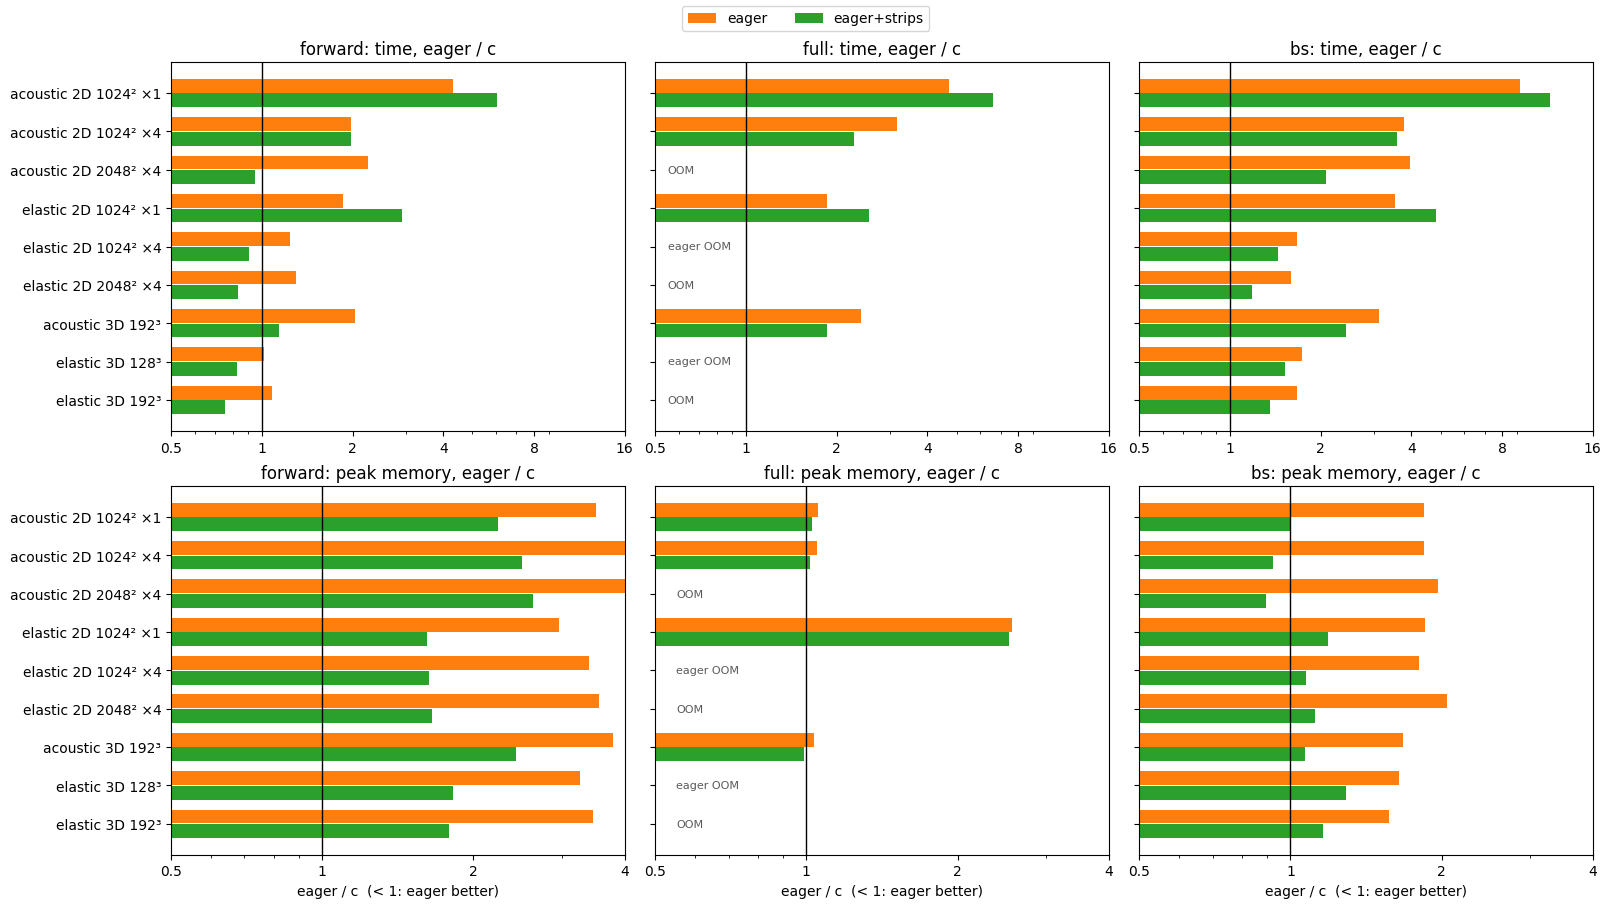

In [5]:
from matplotlib.ticker import FuncFormatter, NullFormatter

labels = [case[0] for case in CASES]
y = np.arange(len(labels))
colors = {'eager': 'tab:orange', 'eager+strips': 'tab:green'}


def oom_note(case, workload):
    bad = [n for n, _ in IMPLS if 'error' in results[case[0], workload, n]]
    if not bad:
        return ''
    if len(bad) == len(IMPLS):
        return 'OOM'
    return 'eager OOM' if bad == ['eager', 'eager+strips'] else 'OOM: ' + ', '.join(bad)


fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True, constrained_layout=True)
for row, (key, title, lim, ticks) in enumerate((('time', 'time', (0.5, 16), [0.5, 1, 2, 4, 8, 16]),
                                                ('peak', 'peak memory', (0.5, 4), [0.5, 1, 2, 4]))):
    for col, workload in enumerate(WORKLOADS):
        ax = axes[row, col]
        for k, (name, _) in enumerate(IMPLS[:2]):
            vals = []
            for case in CASES:
                r, c = results[case[0], workload, name], results[case[0], workload, 'c']
                vals.append(r[key] / c[key] if 'error' not in r and 'error' not in c else np.nan)
            ax.barh(y + (k - 0.5) * 0.38, vals, height=0.36, color=colors[name], label=name)
        for i, case in enumerate(CASES):
            note = oom_note(case, workload)
            if note:
                ax.text(0.55, i, note, va='center', fontsize=8, color='0.35')
        ax.axvline(1.0, color='k', lw=1)
        ax.set_xscale('log')
        ax.set_xlim(*lim)
        ax.set_xticks(ticks)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(f'{workload}: {title}, eager / c')
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
axes[0, 0].invert_yaxis()                     # shared: invert once
for ax in axes[1]:
    ax.set_xlabel('eager / c  (< 1: eager better)')
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc='outside upper center', ncol=2)
plt.show()

## 5. Reading the numbers

- **Forward.** On the large grids eager with strips is the faster one: 0.76–0.91×
  the `c` time on elastic 2-D (four shots) and 3-D and 0.95× on acoustic 2-D at
  2048² × 4; acoustic 3-D at 192³ is about level (1.14×). The strips are what
  does it: without them eager is at best level with `c`. On a small
  single-shot grid a time step is too short for the GPU to matter, so eager's
  per-step launches dominate and it is 2–4× slower. Its memory is higher in
  every forward case (1.6–2.6×; `c` updates the fields in place), but small in
  absolute terms.
- **Full storage.** `c` is faster wherever both fit (1.9–4.7×). Memory is
  level for acoustic (0.99–1.03×) but not for elastic: with every model taking
  a gradient, autograd also keeps the velocity derivatives that the vs and rho
  gradients need, so eager uses 2.5× the memory at 1024² × 1 and runs out at
  1024² × 4 and on the 128³ elastic cube, where `c` still fits. Full storage
  itself runs out on the largest grids for both.
- **Boundary saving.** `c` is faster in every case: 1.2–2.4× on the large and
  3-D grids, 3.5–9.2× on the small ones. With strips, eager's memory is close
  to `c` (0.89–1.29×).
- **First call.** eager compiles its time step on the first call: 2–12 s for
  the forward, 4–12 s for a full-storage gradient and up to 49 s for a 3-D
  boundary-saving gradient. It is cached on disk, so later runs skip it; `c`
  has no compile step.
- **Same answer.** The eager and `c` gradients agree to 1e-4 or better
  (relative L2) in every case both ran.

### Which one to use

| situation | pick |
| --- | --- |
| forward modelling on a large grid or many shots | eager, `EagerOptions(cpml_strips=True)` |
| gradients, full storage or boundary saving | `c` |
| a small grid with one shot | `c` |
| something only eager has: a new equation written in Python, a source-wavelet gradient where `c` returns none, 3-D elastic with image-method topography | eager |